In [1]:
import pandas as pd
import numpy as np
import os
import torch
import torch.nn.functional as F
import seaborn as sns
import random
import pickle
import matplotlib.gridspec as gridspec



from scipy.spatial.distance import pdist, squareform
from scipy.stats import pearsonr, spearmanr
from scipy.stats import rankdata
from matplotlib import pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve, auc
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


from Bio import pairwise2
from Bio.Seq import Seq
from Bio.Align import substitution_matrices
from Bio import SeqIO

from random import sample

from utils_for_analysis import (
    calculate_ss_for_df_and_factors,
    load_df_all,
    load_df_with_budget,
    discretized_parameter_scale,
    xlabel_dict,
    ylabel_dict,
    title_fontsize,
    label_fontsize,
    tick_fontsize,
    legend_fontsize,
    original_parameter_scale,
    color_map,
    fix_ticks,
    get_labels,
    positions,
    num_muts_column_name,
    DATASET_PATHS,
    plot_exporter
)


/home/labs/fleishman/itayta/.conda/envs/esm_env/lib/python3.10/site-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


In [2]:

def get_relevant_columns_gfp_protgym(df, first_col, last_col):
    si = np.where(df.columns == first_col)[0][0]
    ei = np.where(df.columns == last_col)[0][0]+1
    return df.columns[si:ei]

def nmt_relevant_columns(df):
    si = np.where(df.columns == "1")[0][0]
    ei = np.where(df.columns == "272")[0][0]+1
    positions_with_mutations =  np.array([len(pd.unique(df.iloc[:,i])) > 1 for i in range(si,ei)])
    return df.columns[si:ei][positions_with_mutations]

def get_relevant_columns(dataset, df):
    cols = get_relevant_columns_gfp_protgym(df, positions[dataset][0], positions[dataset][1])
    return cols



# --- OHE Feature Creation ---
def get_one_hot_encoding(sdf, relevant_columns):
    one_hot_encoding = pd.get_dummies(sdf[relevant_columns])
    return one_hot_encoding

datasets_and_activity = {
    "gcn4": {"path": "./data/gcn4/gcn4.csv", "activity_col": "activity"},
    "pard3": {"path": "./data/pard3/pard3.csv", "activity_col": "activity"},
    "pte": {"path": "./data/pte/pte.csv", "activity_col": "p-nitrophenyl_octanoate"},
    "nmt": {"path": "./data/nmt/nmt_full_seq.csv", "activity_col": "activity"},
    "lov": {"path": "./data/lov/lov.csv", "activity_col": "activity"},
    "gfp": {"path": "./data/gfp/gfp_dataset_10mut.csv", "activity_col": "inactive"},
    "aamyl": {"path": "./data/aamyl/aamyl.csv", "activity_col": "activity"},
    "trpb": {"path": "./data/trpb/trpb.csv", "activity_col": "activity"},
    "his": {"path": "./data/his/his.csv", "activity_col": "activity"},
    "casp": {"path": "./data/casp/casp.csv", "activity_col": "activity"}
}

names_dict = {
    "esm2_t6_8M_UR50D": "ESM2 (8m)", 
    "esm2_t12_35M_UR50D": "ESM2 (35m)", 
    "esm2_t30_150M_UR50D": "ESM2 (150m)", 
    "esm2_t33_650M_UR50D" : "ESM2 (650m)",
    "pssm": "PSSM"
}





In [3]:
export_plot = plot_exporter("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis")

In [106]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt


# def plot_feature_metric_grid(
#     df,
#     panel_config,
#     dataset_col="dataset",
#     group_col="feature_name",
#     center="mean",
#     error="sd",
#     n_train=None,
#     n_train_col="n_train",
#     feature_order=None,
#     reference_feature="OHE",
#     reference_color="black",
#     reference_linestyle="--",
#     reference_linewidth=1,
#     figsize=None,
#     text_size=8,
#     marker_size=4,
#     capsize=3,
#     xlim=None,
#     wspace=0.08,
#     hspace=0.18,
# ):
#     """
#     Plot mean/median metric values for features in a configurable grid.

#     The vertical line in each panel shows the value of reference_feature.
#     """
#     if center not in {"mean", "median"}:
#         raise ValueError("center must be 'mean' or 'median'.")

#     if error not in {"sd", "sem", None}:
#         raise ValueError("error must be 'sd', 'sem', or None.")

#     if not panel_config or not any(panel_config):
#         raise ValueError("panel_config cannot be empty.")

#     plot_df = df.copy()

#     if n_train is not None:
#         plot_df = plot_df[plot_df[n_train_col] == n_train]

#     panels = [tuple(panel) for row in panel_config for panel in row]
#     missing_metrics = sorted({metric for _, metric in panels if metric not in plot_df})

#     if missing_metrics:
#         raise ValueError(f"Missing metric columns: {missing_metrics}")

#     def summarize(dataset, metric):
#         work = plot_df.loc[
#             plot_df[dataset_col] == dataset,
#             [group_col, metric],
#         ].copy()

#         work[metric] = pd.to_numeric(work[metric], errors="coerce")
#         work = work.dropna(subset=[group_col, metric])

#         summary = work.groupby(group_col)[metric].agg(
#             mean="mean",
#             median="median",
#             sd="std",
#             n="count",
#         )
#         summary["sem"] = summary["sd"] / np.sqrt(summary["n"])

#         return summary

#     summaries = {
#         (dataset, metric): summarize(dataset, metric)
#         for dataset, metric in panels
#     }

#     if feature_order is None:
#         reference = next(
#             (summary for summary in summaries.values() if not summary.empty),
#             None,
#         )

#         if reference is None:
#             raise ValueError("No data were found for the requested panels.")

#         feature_order = reference.sort_values(center).index.tolist()
#         seen = set(feature_order)

#         for summary in summaries.values():
#             for feature in summary.index:
#                 if feature not in seen:
#                     feature_order.append(feature)
#                     seen.add(feature)
#     else:
#         feature_order = list(feature_order)

#     nrows = len(panel_config)
#     ncols = max(len(row) for row in panel_config)
#     panel_height = max(2.2, 0.28 * len(feature_order))
#     figsize = figsize or (2.7 * ncols, panel_height * nrows)

#     fig, axes = plt.subplots(
#         nrows,
#         ncols,
#         figsize=figsize,
#         sharex=True,
#         sharey=True,
#         squeeze=False,
#     )

#     y = np.arange(len(feature_order))

#     last_row_by_column = [
#         max(row_index for row_index, row in enumerate(panel_config) if column < len(row))
#         for column in range(ncols)
#     ]

#     for row_index, row in enumerate(panel_config):
#         for column_index in range(ncols):
#             ax = axes[row_index, column_index]

#             if column_index >= len(row):
#                 ax.set_visible(False)
#                 continue

#             dataset, metric = row[column_index]
#             summary = summaries[(dataset, metric)].reindex(feature_order)

#             values = summary[center].to_numpy(dtype=float)
#             valid = np.isfinite(values)

#             if reference_feature is not None and reference_feature in summary.index:
#                 reference_value = summary.loc[reference_feature, center]

#                 if np.isfinite(reference_value):
#                     ax.axvline(
#                         reference_value,
#                         color=reference_color,
#                         linestyle=reference_linestyle,
#                         linewidth=reference_linewidth,
#                         zorder=0,
#                     )

#             if error is None:
#                 errors = None
#             else:
#                 errors = summary[error].to_numpy(dtype=float)
#                 errors = np.where(np.isfinite(errors), errors, 0)
#                 errors = errors[valid]

#             ax.errorbar(
#                 values[valid],
#                 y[valid],
#                 xerr=errors,
#                 fmt="o",
#                 color="black",
#                 markersize=marker_size,
#                 capsize=capsize,
#                 linestyle="none",
#                 zorder=2,
#             )

#             ax.set_title(f"{dataset} | {metric}", fontsize=text_size, pad=3)
#             ax.set_ylabel("")
#             ax.tick_params(axis="both", labelsize=text_size)

#             if column_index == 0:
#                 ax.set_yticks(y)
#                 ax.set_yticklabels(feature_order)
#             else:
#                 ax.tick_params(axis="y", labelleft=False)

#             is_bottom = row_index == last_row_by_column[column_index]
#             ax.set_xlabel("Value" if is_bottom else "", fontsize=text_size)

#             if not is_bottom:
#                 ax.tick_params(axis="x", labelbottom=False)

#     if xlim is not None:
#         axes[0, 0].set_xlim(*xlim)

#     fig.tight_layout(pad=0.3)
#     fig.subplots_adjust(wspace=wspace, hspace=hspace)

#     return fig, axes

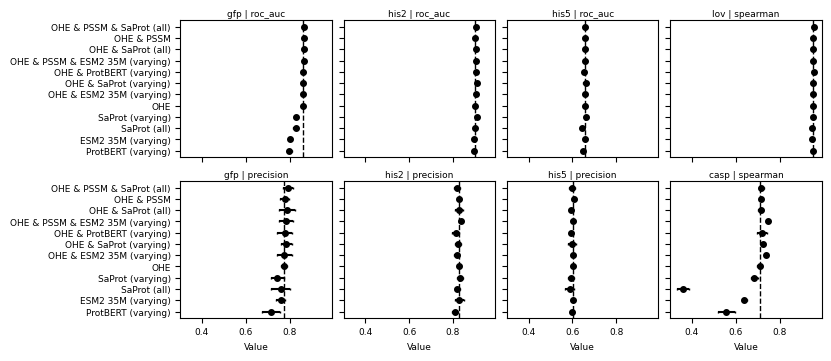

In [ ]:
# panel_config = [
#     [["gfp", "roc_auc"], ["his2", "roc_auc"], ["his5", "roc_auc"], ["lov", "spearman"]],
#     [["gfp", "precision"], ["his2", "precision"], ["his5", "precision"], ["casp", "spearman"]],
# ]

# fig, axes = plot_feature_metric_grid(
#     scoring_results_df[scoring_results_df["n_train"] <= 2000],
#     panel_config=panel_config,
#     center="median",
#     error="sd",
#     n_train=1000,
#     figsize=(8.2, 3.5),
#     text_size=6.5,
#     capsize=1,
#         reference_feature="OHE",
# )

# plt.show()

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


panel_labels = {
    "correlation": r"Spearman's $\rho$",
    "spearman": r"Spearman's $\rho$",
    "roc_auc": "ROC-AUC",
    "precision": "Precision",
}


def plot_feature_metric_box_grid(
    df,
    panel_config,
    dataset_col="dataset",
    group_col="feature_name",
    center="median",
    n_train=None,
    n_train_col="n_train",
    feature_order=None,
    reference_feature="OHE",
    reference_color="black",
    reference_linestyle="--",
    reference_linewidth=1,
    box_color="#3665A7",
    box_width=0.6,
    box_alpha=0.7,
    box_edgecolor="black",
    box_linewidth=0.8,
    highlight_feature="OHE",
    highlight_color="#D73027",
    showfliers=False,
    figsize=None,
    text_size=8,
    full_xlabel=True,
    custom_range=None,
    x_margin=0.05,
    wspace=0.08,
    hspace=0.35,
):
    """Plot horizontal boxplots with an independent x-range for every panel."""
    if center not in {"mean", "median"}:
        raise ValueError("center must be 'mean' or 'median'.")

    if not panel_config or not any(panel_config):
        raise ValueError("panel_config cannot be empty.")

    if custom_range is not None:
        if not isinstance(custom_range, dict):
            raise ValueError("custom_range must be None or a dictionary.")

        for dataset, limits in custom_range.items():
            if not isinstance(limits, (list, tuple)) or len(limits) != 2:
                raise ValueError(f"Invalid range for {dataset!r}: {limits}")

    plot_df = df.copy()

    if n_train is not None:
        plot_df = plot_df[plot_df[n_train_col] == n_train]

    panels = [tuple(panel) for row in panel_config for panel in row]
    missing_metrics = sorted({metric for _, metric in panels if metric not in plot_df})

    if missing_metrics:
        raise ValueError(f"Missing metric columns: {missing_metrics}")

    def prepare_panel(dataset, metric):
        work = plot_df.loc[plot_df[dataset_col] == dataset, [group_col, metric]].copy()
        work["value"] = pd.to_numeric(work[metric], errors="coerce")
        return work[[group_col, "value"]].dropna()

    panel_data = {
        (dataset, metric): prepare_panel(dataset, metric)
        for dataset, metric in panels
    }

    if feature_order is None:
        reference = next((work for work in panel_data.values() if not work.empty), None)

        if reference is None:
            raise ValueError("No data were found for the requested panels.")

        feature_order = (
            reference.groupby(group_col)["value"].agg(center).sort_values().index.tolist()
        )
        seen = set(feature_order)

        for work in panel_data.values():
            for feature in pd.unique(work[group_col]):
                if feature not in seen:
                    feature_order.append(feature)
                    seen.add(feature)
    else:
        feature_order = list(feature_order)

    nrows = len(panel_config)
    ncols = max(len(row) for row in panel_config)
    panel_height = max(2.2, 0.28 * len(feature_order))
    figsize = figsize or (2.7 * ncols, panel_height * nrows)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=figsize,
        sharex=False,
        sharey=True,
        squeeze=False,
    )

    y = np.arange(len(feature_order))

    for row_index, row in enumerate(panel_config):
        for column_index in range(ncols):
            ax = axes[row_index, column_index]

            if column_index >= len(row):
                ax.set_visible(False)
                continue

            dataset, metric = row[column_index]
            metric_label = panel_labels.get(metric, metric.replace("_", " ").title())
            work = panel_data[(dataset, metric)]

            boxplot_data = []
            boxplot_positions = []
            boxplot_features = []

            for position, feature in enumerate(feature_order):
                values = work.loc[work[group_col] == feature, "value"].to_numpy()

                if len(values):
                    boxplot_data.append(values)
                    boxplot_positions.append(position)
                    boxplot_features.append(feature)

            if boxplot_data:
                bp = ax.boxplot(
                    boxplot_data,
                    positions=boxplot_positions,
                    vert=False,
                    widths=box_width,
                    patch_artist=True,
                    showfliers=showfliers,
                    manage_ticks=False,
                    boxprops={
                        "color": box_edgecolor,
                        "linewidth": box_linewidth,
                    },
                    medianprops={
                        "color": "black",
                        "linewidth": 1,
                    },
                    whiskerprops={
                        "color": box_edgecolor,
                        "linewidth": box_linewidth,
                    },
                    capprops={
                        "color": box_edgecolor,
                        "linewidth": box_linewidth,
                    },
                    flierprops={
                        "marker": "o",
                        "markerfacecolor": "black",
                        "markeredgecolor": "black",
                        "markersize": 2.5,
                        "linestyle": "none",
                    },
                )

                for patch, feature in zip(bp["boxes"], boxplot_features):
                    color = highlight_color if feature == highlight_feature else box_color
                    patch.set_facecolor(color)
                    patch.set_alpha(box_alpha)

            if reference_feature is not None:
                reference_values = work.loc[
                    work[group_col] == reference_feature,
                    "value",
                ]

                if len(reference_values):
                    reference_value = reference_values.agg(center)

                    ax.axvline(
                        reference_value,
                        color=reference_color,
                        linestyle=reference_linestyle,
                        linewidth=reference_linewidth,
                        zorder=4,
                    )

            dataset_range = None if custom_range is None else custom_range.get(dataset)

            if dataset_range is None:
                ax.relim()
                ax.autoscale_view(scalex=True)
                ax.margins(x=x_margin)
            else:
                ax.set_xlim(*dataset_range)

            xlabel = metric_label if full_xlabel else "Value"

            ax.set_title(str(dataset), fontsize=text_size, pad=2)
            ax.set_xlabel(xlabel, fontsize=text_size, labelpad=1)
            ax.set_ylabel("")
            ax.tick_params(axis="both", labelsize=text_size)
            ax.set_axisbelow(True)

            ax.grid(
                axis="y",
                color="#D9D9D9",
                linestyle="-",
                linewidth=0.5,
                alpha=0.7,
            )

            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)

            if column_index == 0:
                ax.set_yticks(y)
                ax.set_yticklabels(feature_order)
            else:
                ax.tick_params(axis="y", labelleft=False)

    fig.tight_layout(pad=0.2)
    fig.subplots_adjust(wspace=wspace, hspace=hspace)

    return fig, axes

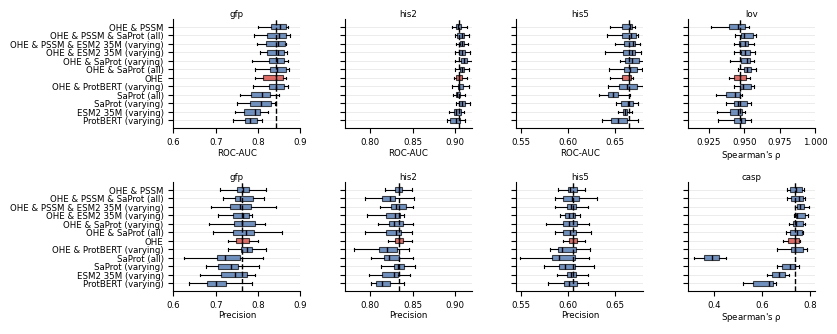

In [53]:
panel_config = [
    [["gfp", "roc_auc"], ["his2", "roc_auc"], ["his5", "roc_auc"], ["lov", "spearman"]],
    [["gfp", "precision"], ["his2", "precision"], ["his5", "precision"], ["casp", "spearman"]],
]


final_df_subset = pd.read_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/feature_combination/feature_comb.csv")
fig, axes = plot_feature_metric_box_grid(
    final_df_subset  ,#scoring_results_df[scoring_results_df["n_train"] <= 2000],#scoring_results_df,
    panel_config=panel_config,
    center="median",
    #error="sd",
    #n_train=1000,
    figsize=(8.2, 3.2),
    reference_feature="OHE",
    #bar_color="#3665A7",
    #bar_height=0.55,
    #capsize=0,
    text_size=6.25,
    wspace=0.35,
    hspace=0.5,
    custom_range ={
    "his2": (0.77, 0.92),
    "his5": (0.545, 0.68),
    "gfp": (0.6, 0.9),
    "lov": (0.91, 1)
}
)


export_plot("ohe_and_models_multifeature_scoring")
plt.show()

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from scipy.stats import rankdata, spearmanr, pearsonr


def plot_distance_heatmaps(
    ohe,
    emb,
    subsample=None,
    random_state=0,
    cmap="mako",
    show_colorbar=True,
    figsize=(8, 3.5),
    text_size=8,
    titles=("Onehot Hamming Distance", "Embedding Cosine Distance"),
    linkage_method="average",
    cluster_by_ohe=False,
):
    ohe = np.asarray(ohe)
    emb = np.asarray(emb)

    if ohe.shape != emb.shape:
        raise ValueError("Matrices must have the same shape.")

    n = ohe.shape[0]

    if subsample is not None:
        rng = np.random.default_rng(random_state)
        idx = rng.choice(n, size=subsample, replace=False)
        ohe = ohe[np.ix_(idx, idx)]
        emb = emb[np.ix_(idx, idx)]

    triu = np.triu_indices_from(ohe, k=1)
    rho_all, pval = pearsonr(ohe[triu], emb[triu])

    def rank_norm(x):
        mask = ~np.eye(len(x), dtype=bool)
        vals = x[mask]
        ranks = rankdata(vals, method="average")
        ranks = (ranks - 1) / (len(ranks) - 1)

        out = np.zeros_like(x, dtype=float)
        out[mask] = ranks

        return out

    if cluster_by_ohe:
        emb_cluster = (ohe + ohe.T) / 2
        np.fill_diagonal(emb_cluster, 0)
    else:
        emb_cluster = (emb + emb.T) / 2
        np.fill_diagonal(emb_cluster, 0)

    condensed = squareform(emb_cluster, checks=False)
    Z = linkage(condensed, method=linkage_method)
    order = leaves_list(Z)

    ohe = rank_norm(ohe)
    emb = rank_norm(emb)

    ohe = ohe[np.ix_(order, order)]
    emb = emb[np.ix_(order, order)]

    if show_colorbar:
        fig = plt.figure(figsize=figsize)
        gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.045], wspace=0.08)

        axs = np.array([
            fig.add_subplot(gs[0, 0]),
            fig.add_subplot(gs[0, 1]),
        ])

        cax = fig.add_subplot(gs[0, 2])

    else:
        fig, axs = plt.subplots(1, 2, figsize=figsize)
        cax = None

    sns.heatmap(
        ohe,
        ax=axs[0],
        cmap=cmap,
        vmin=0,
        vmax=1,
        square=True,
        xticklabels=False,
        yticklabels=False,
        cbar=False,
    )

    sns.heatmap(
        emb,
        ax=axs[1],
        cmap=cmap,
        vmin=0,
        vmax=1,
        square=True,
        xticklabels=False,
        yticklabels=False,
        cbar=show_colorbar,
        cbar_ax=cax,
        cbar_kws={"label": "Distance percentile"} if show_colorbar else None,
    )

    axs[0].set_title(titles[0], fontsize=text_size, pad=3)
    axs[1].set_title(titles[1], fontsize=text_size, pad=3)

    fig.suptitle(
        rf"Spearman $\rho$ = {rho_all:.3f}",
        fontsize=text_size,
        y=0.96,
    )

    fig.subplots_adjust(
        left=0.03,
        right=0.97,
        bottom=0.04,
        top=0.84,
    )

    return fig, axs

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/nmt_pairwise_hamming_and_cosine_full_saprot.png


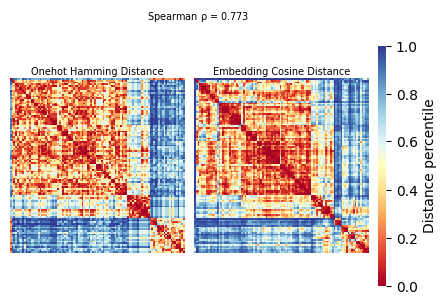

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/gfp_pairwise_hamming_and_cosine_full_saprot.png


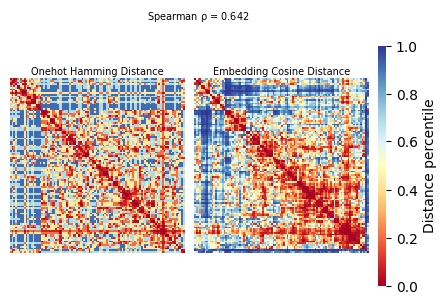

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/casp_pairwise_hamming_and_cosine_full_saprot.png


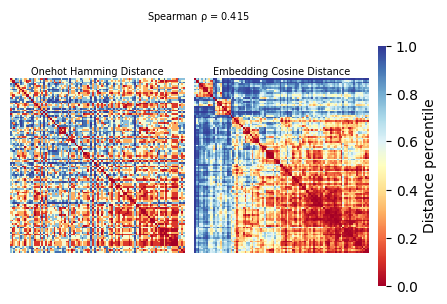

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/pard3_pairwise_hamming_and_cosine_full_saprot.png


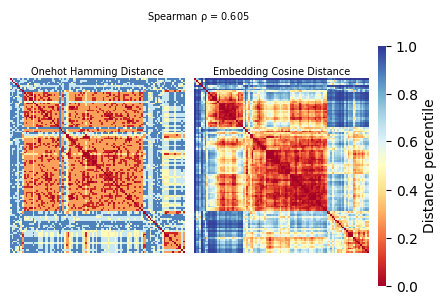

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/lov_pairwise_hamming_and_cosine_full_saprot.png


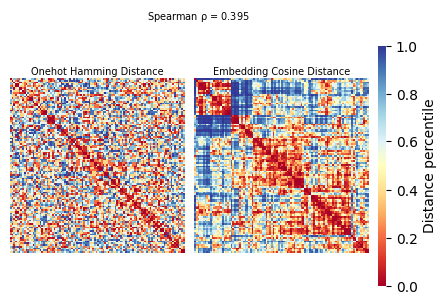

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/his5_pairwise_hamming_and_cosine_full_saprot.png


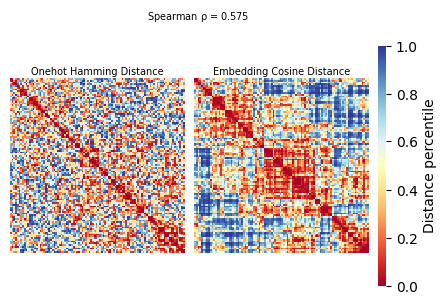

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/his2_pairwise_hamming_and_cosine_full_saprot.png


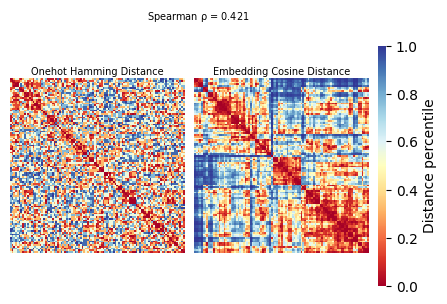

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/nmt_pairwise_hamming_and_cosine_partial_saprot.png


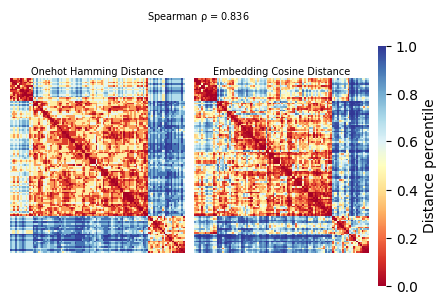

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/gfp_pairwise_hamming_and_cosine_partial_saprot.png


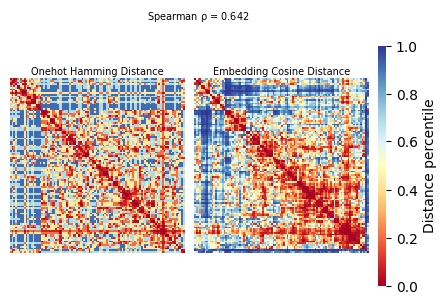

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/casp_pairwise_hamming_and_cosine_partial_saprot.png


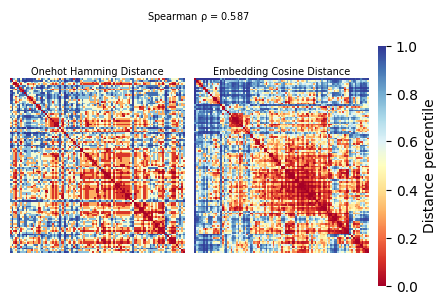

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/pard3_pairwise_hamming_and_cosine_partial_saprot.png


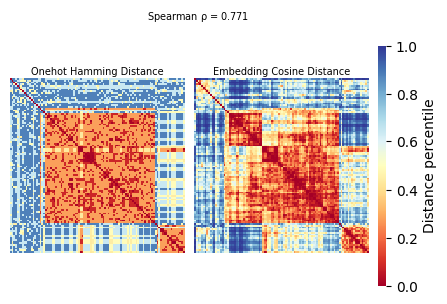

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/lov_pairwise_hamming_and_cosine_partial_saprot.png


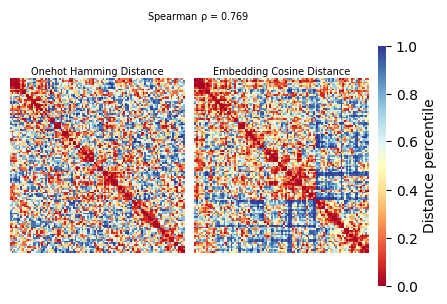

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/his5_pairwise_hamming_and_cosine_partial_saprot.png


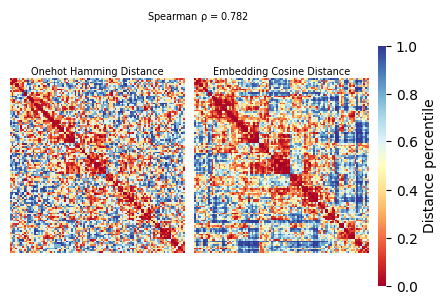

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/his2_pairwise_hamming_and_cosine_partial_saprot.png


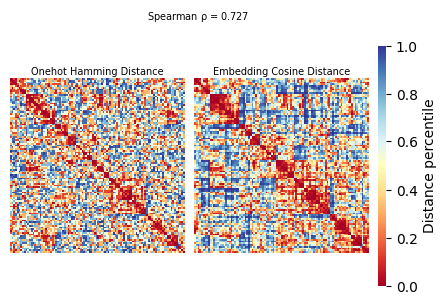

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/nmt_pairwise_hamming_and_cosine_partial_protbert.png


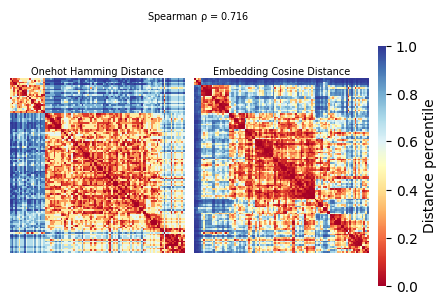

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/gfp_pairwise_hamming_and_cosine_partial_protbert.png


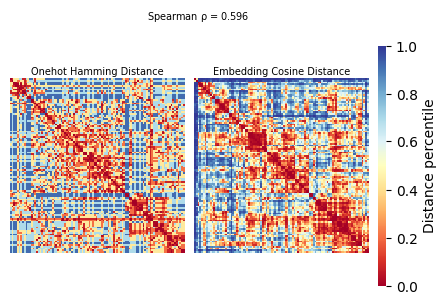

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/casp_pairwise_hamming_and_cosine_partial_protbert.png


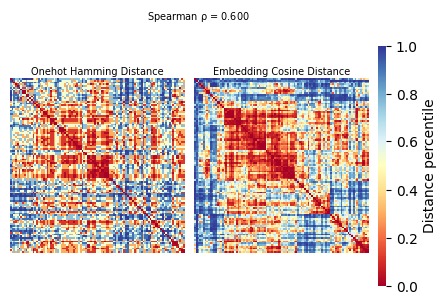

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/pard3_pairwise_hamming_and_cosine_partial_protbert.png


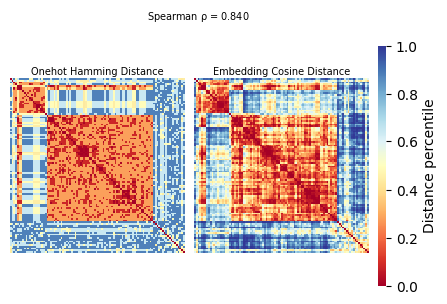

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/lov_pairwise_hamming_and_cosine_partial_protbert.png


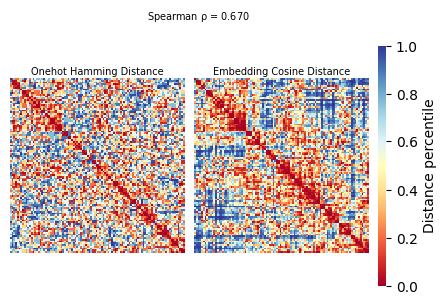

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/his5_pairwise_hamming_and_cosine_partial_protbert.png


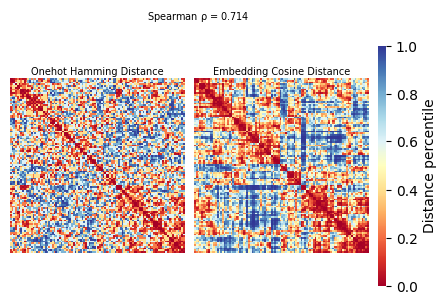

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/his2_pairwise_hamming_and_cosine_partial_protbert.png


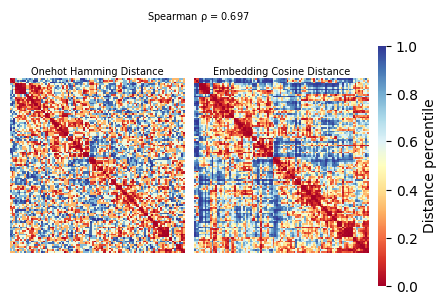

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/nmt_pairwise_hamming_and_cosine_partial_esm_35m.png


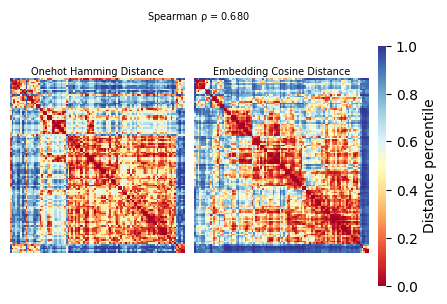

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/gfp_pairwise_hamming_and_cosine_partial_esm_35m.png


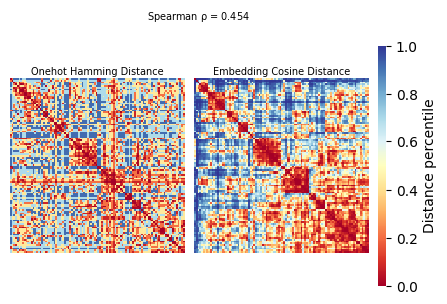

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/casp_pairwise_hamming_and_cosine_partial_esm_35m.png


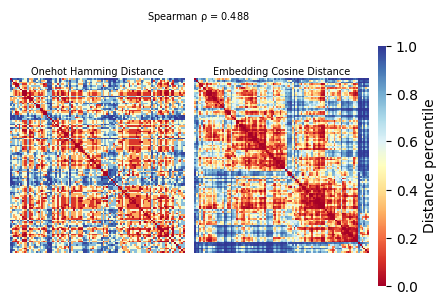

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/pard3_pairwise_hamming_and_cosine_partial_esm_35m.png


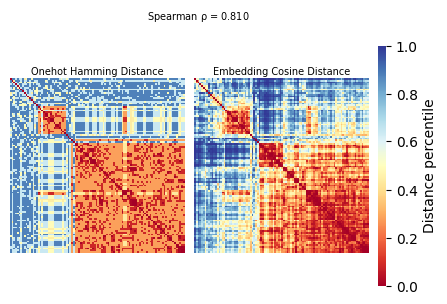

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/lov_pairwise_hamming_and_cosine_partial_esm_35m.png


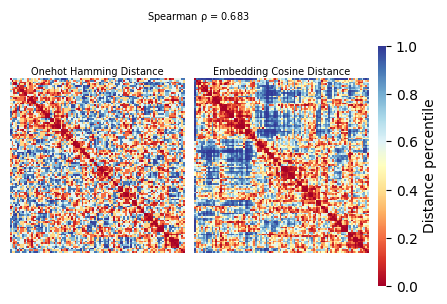

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/his5_pairwise_hamming_and_cosine_partial_esm_35m.png


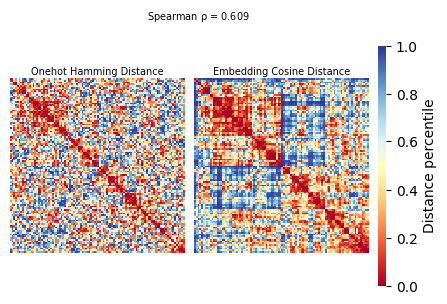

/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/his2_pairwise_hamming_and_cosine_partial_esm_35m.png


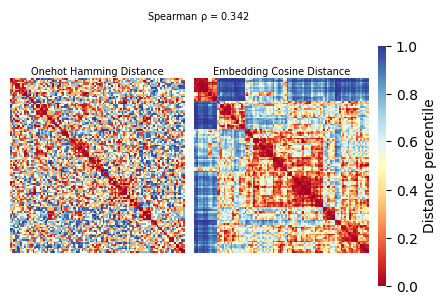

In [57]:
for model in ["full_saprot", "partial_saprot", "partial_protbert", "partial_esm_35m"]:
    for ds in ["nmt", "gfp", "casp", "pard3", "lov", "his5", "his2"]:

        base = (
            "/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/"
            f"notebooks/data/merged_datasets/feature_combination/{ds}/"
            f"reconstruction_analysis/{model}_mean/"
        )

        a = np.load(base + "sample_pairwise_onehot_hamming_distance.npy")
        b = np.load(base + "sample_pairwise_embedding_cosine_distance.npy")

        fig, ax = plot_distance_heatmaps(
            a,
            b,
            subsample=100,
            cmap="RdYlBu",#inferno",
            cluster_by_ohe=False,
            show_colorbar=True,
            figsize=(4, 3),
            text_size=7,
        )

        save_path = export_plot(
            f"{ds}_pairwise_hamming_and_cosine_{model}",
            fig=fig,
        )

        save_path = export_plot(
            f"{ds}_pairwise_hamming_and_cosine_{model}",
            fig=fig,
            file_format='png'
        )

        print(save_path)

        plt.show()
        plt.close(fig)

PosixPath('/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/revised_figures/ohe_emb_feature_analysis/gfp_pairwise_hamming_and_cosine_full_saprot.svg')

<Figure size 640x480 with 0 Axes>

In [10]:

all = []
for dataset in ["lov", "casp", "pard3", "gfp", "nmt", "his2", "his5"]:
    example = pd.read_csv("/home/labs/fleishman/itayta/new_fitness_repo/fitness_learning/notebooks/data/merged_datasets/feature_combination/%s/new_features.csv" % dataset)
    all.append(example)

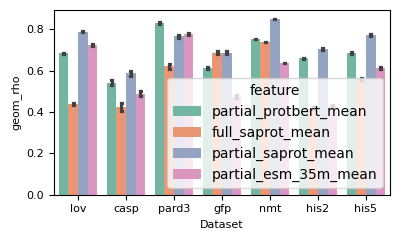

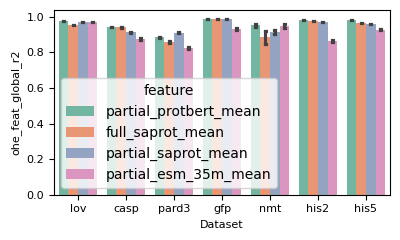

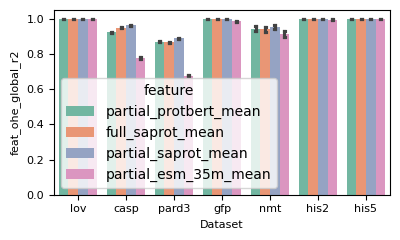

In [56]:
all_recon = pd.concat(all)
def plot_feature_violins(
    df,
    metric="geom_rho",
    dataset_order=None,
    feature_order=None,
    figsize=(10, 4),
    text_size=8,
    palette="Set2",
    inner="box",
    plot_type="violin",
):
    data = df.copy()

    if metric is not None:
        data = data[data["metric"] == metric]

    if dataset_order is None:
        dataset_order = data["dataset"].unique()

    if feature_order is None:
        feature_order = data["feature"].unique()

    fig, ax = plt.subplots(figsize=figsize)

    if plot_type == "violin":
        sns.violinplot(
            data=data,
            x="dataset",
            y="value",
            hue="feature",
            order=dataset_order,
            hue_order=feature_order,
            palette=palette,
            inner=inner,
            cut=0,
            density_norm="width",
            ax=ax,
        )

    elif plot_type == "bar":
        sns.barplot(
            data=data,
            x="dataset",
            y="value",
            hue="feature",
            order=dataset_order,
            hue_order=feature_order,
            palette=palette,
            estimator=np.mean,
            errorbar="sd",
            capsize=0.08,
            ax=ax,
        )

    else:
        raise ValueError("plot_type must be 'violin' or 'bar'.")

    ax.set_xlabel("Dataset", fontsize=text_size)
    ax.set_ylabel(metric if metric is not None else "Value", fontsize=text_size)
    ax.tick_params(axis="both", labelsize=text_size)

    # if ax.get_legend() is not None:
    #     ax.get_legend().remove()

    plt.tight_layout()

    return fig, ax

fig, ax = plot_feature_violins(
    all_recon[all_recon["metric"] == "geom_rho"],
    metric="geom_rho",
    figsize=(4.1, 2.5),
    text_size=8,
    palette="Set2",
    plot_type="bar"
    
)

save_path = export_plot(
            f"spearman_corr",
            fig=fig,
        )


fig, ax = plot_feature_violins(
    all_recon[all_recon["metric"] == "ohe_feat_global_r2"],
    metric="ohe_feat_global_r2",
    figsize=(4.1, 2.5),
    text_size=8,
    palette="Set2",
    plot_type="bar"
    
)

save_path = export_plot(
            f"ohe_to_feat_r2",
            fig=fig,
        )



fig, ax = plot_feature_violins(
    all_recon[all_recon["metric"] == "feat_ohe_global_r2"],
    metric="feat_ohe_global_r2",
    figsize=(4.1, 2.5),
    text_size=8,
    plot_type="bar",
    palette="Set2",

    )


save_path = export_plot(
            f"feat_to_ohe_r2",
            fig=fig,
        )




In [86]:
all_recon[all_recon["metric"] == "ohe_feat_r2"]

,dataset,iteration,feature,metric,alpha,train_size,test_size,value
2,lov,1,partial_protbert_mean,ohe_feat_r2,10.0,750,750,0.978074
14,lov,2,partial_protbert_mean,ohe_feat_r2,10.0,750,750,0.978291
26,lov,3,partial_protbert_mean,ohe_feat_r2,10.0,750,750,0.977957
38,lov,4,partial_protbert_mean,ohe_feat_r2,10.0,750,750,0.978013
50,lov,5,partial_protbert_mean,ohe_feat_r2,10.0,750,750,0.978157
...,...,...,...,...,...,...,...,...
1382,his5,26,partial_esm_35m_mean,ohe_feat_r2,10.0,750,750,0.926154
1394,his5,27,partial_esm_35m_mean,ohe_feat_r2,10.0,750,750,0.927109
1406,his5,28,partial_esm_35m_mean,ohe_feat_r2,10.0,750,750,0.927870
1418,his5,29,partial_esm_35m_mean,ohe_feat_r2,10.0,750,750,0.926794


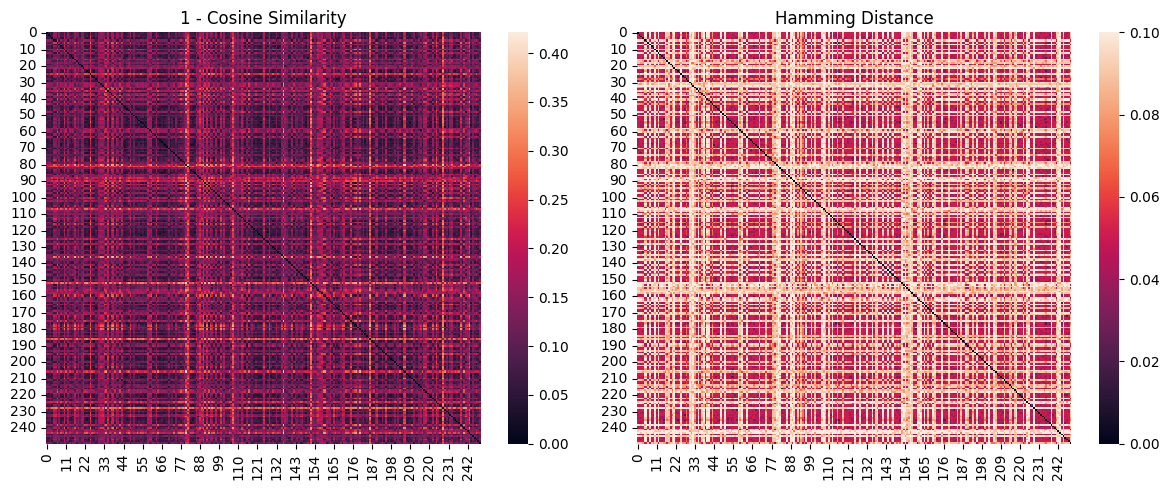

In [ ]:
# from sklearn.preprocessing import minmax_scale


# cos_sim = 1 - cosine_similarity_matrix
# ham_sim = hamming_dist_matrix
# #cos_sim = minmax_scale(cos_sim.flatten(), axis=0).reshape(cosine_similarity_matrix.shape)
# #ham_sim = minmax_scale(ham_sim.flatten(), axis=0).reshape(hamming_dist_matrix.shape)

# fig, axs = plt.subplots(1, 2, figsize=(12, 5))
# sns.heatmap(cos_sim, ax=axs[0])
# axs[0].set_title("1 - Cosine Similarity")
# sns.heatmap(ham_sim, ax=axs[1])
# axs[1].set_title("Hamming Distance")
# plt.tight_layout()
# plt.show()

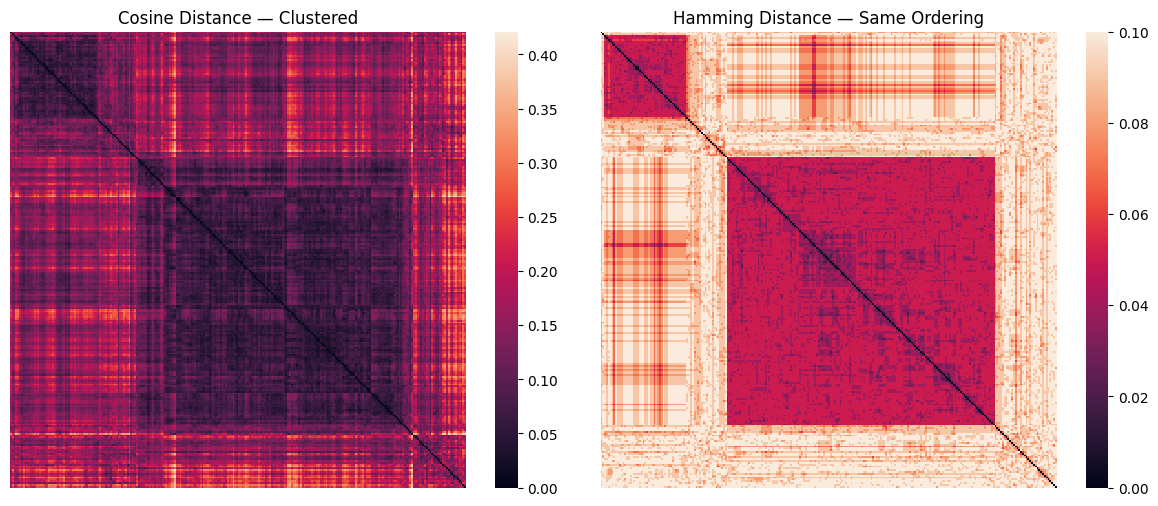

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns

# from scipy.cluster.hierarchy import linkage, leaves_list
# from scipy.spatial.distance import squareform
# from sklearn.preprocessing import minmax_scale

# cos_dist = np.asarray(1 - cosine_similarity_matrix, dtype=float)
# ham_dist = np.asarray(hamming_dist_matrix, dtype=float)

# assert cos_dist.shape == ham_dist.shape
# assert cos_dist.ndim == 2
# assert cos_dist.shape[0] == cos_dist.shape[1]

# cos_dist = np.nan_to_num(cos_dist, nan=0.0, posinf=1.0, neginf=0.0)
# ham_dist = np.nan_to_num(ham_dist, nan=0.0, posinf=1.0, neginf=0.0)

# cos_dist = (cos_dist + cos_dist.T) / 2
# ham_dist = (ham_dist + ham_dist.T) / 2

# cos_dist = np.clip(cos_dist, 0, None)
# ham_dist = np.clip(ham_dist, 0, None)

# np.fill_diagonal(cos_dist, 0)
# np.fill_diagonal(ham_dist, 0)


# # Normalize the two distances before combining them
# cos_scaled = minmax_scale(cos_dist.ravel()).reshape(cos_dist.shape)
# ham_scaled = minmax_scale(ham_dist.ravel()).reshape(ham_dist.shape)

# # Equal-weight consensus distance
# combined_dist = 0.5 * cos_scaled + 0.5 * ham_scaled
# np.fill_diagonal(combined_dist, 0)


# # Hierarchical clustering from the precomputed consensus distance
# condensed_dist = squareform(combined_dist, checks=False)

# Z = linkage(
#     condensed_dist,
#     method="average",
#     optimal_ordering=True,
# )

# order = leaves_list(Z)


# # Apply the same ordering to both matrices
# cos_clustered = cos_dist[np.ix_(order, order)]
# ham_clustered = ham_dist[np.ix_(order, order)]


# fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# sns.heatmap(
#     cos_clustered,
#     ax=axs[0],
#     square=True,
#     xticklabels=False,
#     yticklabels=False,
# )
# axs[0].set_title("Cosine Distance — Clustered")

# sns.heatmap(
#     ham_clustered,
#     ax=axs[1],
#     square=True,
#     xticklabels=False,
#     yticklabels=False,
# )
# axs[1].set_title("Hamming Distance — Same Ordering")

# plt.tight_layout()
# plt.show()

In [ ]:
# cosine_similarity_matrix.shape

torch.Size([770, 770])

In [ ]:


# onehot = onehot.astype(float)
# cv = KFold(n_splits=5, shuffle=True, random_state=0)

# X = mean_emb
# Z = onehot
# model = make_pipeline(
#     StandardScaler(),
#     RidgeCV(alphas=np.logspace(-4, 4, 25))
# )

# Z_hat = cross_val_predict(model, X, Z, cv=cv)

# numerator = ((Z - Z_hat) ** 2).sum()
# denominator = ((Z - Z.mean(axis=0)) ** 2).sum()

# global_r2 = 1 - numerator / denominator

# print(global_r2)


# outer_cv = KFold(n_splits=5, shuffle=True, random_state=0)
# inner_cv = KFold(n_splits=5, shuffle=True, random_state=1)

# alphas = np.logspace(-4, 4, 25)
# Z_oof = np.empty_like(Z, dtype=float)

# for train_idx, test_idx in outer_cv.split(X):
#     X_train, X_test = X[train_idx], X[test_idx]
#     Z_train = Z[train_idx]

#     pipeline = Pipeline([
#         ("scale", StandardScaler()),
#         ("ridge", Ridge())
#     ])

#     search = GridSearchCV(
#         pipeline,
#         param_grid={"ridge__alpha": alphas},
#         scoring="neg_mean_squared_error",
#         cv=inner_cv,
#         n_jobs=-1
#     )

#     search.fit(X_train, Z_train)
#     Z_oof[test_idx] = search.predict(X_test)

# feature_r2 = r2_score(
#     Z,
#     Z_oof,
#     multioutput="raw_values"
# )

# weighted_r2 = r2_score(
#     Z,
#     Z_oof,
#     multioutput="variance_weighted"
# )

# print("Variance-weighted R²:", weighted_r2)
# print("Mean feature R²:", np.mean(feature_r2))
# print("Median feature R²:", np.median(feature_r2))
# print("Feature R² percentiles:",
#       np.percentile(feature_r2, [0, 5, 25, 50, 75, 95, 100]))

0.7908496245988088
